# Credit Card Default Risk Model (Probability of Default)
**Data:** "Default of Credit Card Clients" – 30,000 credit card customers, 6 months of repayment history (UCI Machine Learning Repository, CC BY 4.0). Amounts are in New Taiwan dollars (NT$).

**Business question:** Which customers are likely to miss next month's payment, and how can a lender use a risk score to target collections and credit-limit decisions?

Steps: cleaning and data validation → SQL portfolio analysis → feature engineering → Logistic Regression (scorecard-style) vs XGBoost → Gini, KS and risk bands → responsible-use checks.

In [1]:
import pandas as pd, numpy as np, sqlite3, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier
sns.set_theme(style="whitegrid"); pd.set_option("display.width",140)
df = pd.read_excel("data/default_of_credit_card_clients.xls", header=1).rename(columns={"PAY_0":"PAY_1","default payment next month":"DEFAULTED"})
print(df.shape); df.head(3)

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULTED
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 1. Data validation and cleaning

In [2]:
checks = {
 "duplicate IDs": int(df.ID.duplicated().sum()),
 "missing values": int(df.isna().sum().sum()),
 "undocumented EDUCATION codes (0,5,6)": int(df.EDUCATION.isin([0,5,6]).sum()),
 "undocumented MARRIAGE code (0)": int((df.MARRIAGE==0).sum()),
 "customers with a negative bill (credit balance) in latest month": int((df.BILL_AMT1<0).sum()),
 "default rate %": round(df.DEFAULTED.mean()*100,1),
}
print(checks)
df["EDUCATION"] = df.EDUCATION.replace({0:4,5:4,6:4})   # merge unknown codes into 'other'
df["MARRIAGE"]  = df.MARRIAGE.replace({0:3})

{'duplicate IDs': 0, 'missing values': 0, 'undocumented EDUCATION codes (0,5,6)': 345, 'undocumented MARRIAGE code (0)': 54, 'customers with a negative bill (credit balance) in latest month': 590, 'default rate %': np.float64(22.1)}


## 2. Portfolio analysis in SQL

In [3]:
con = sqlite3.connect(":memory:"); df.to_sql("cards", con, index=False)
q = {}
q["default_by_latest_repayment_status"] = """
SELECT CASE WHEN PAY_1 <= 0 THEN 'Paid on time / no balance'
            WHEN PAY_1 = 1 THEN '1 month late' WHEN PAY_1 = 2 THEN '2 months late'
            ELSE '3+ months late' END AS latest_status,
       COUNT(*) AS customers, ROUND(100.0*AVG(DEFAULTED),1) AS default_rate_pct
FROM cards GROUP BY 1 ORDER BY default_rate_pct;"""
q["default_by_credit_limit_band"] = """
WITH b AS (SELECT *, NTILE(5) OVER (ORDER BY LIMIT_BAL) AS band FROM cards)
SELECT band AS limit_quintile, MIN(LIMIT_BAL) AS min_limit, MAX(LIMIT_BAL) AS max_limit,
       COUNT(*) AS customers, ROUND(100.0*AVG(DEFAULTED),1) AS default_rate_pct
FROM b GROUP BY band ORDER BY band;"""
q["default_by_utilisation"] = """
SELECT CASE WHEN 1.0*BILL_AMT1/LIMIT_BAL < 0.3 THEN 'a) under 30%' WHEN 1.0*BILL_AMT1/LIMIT_BAL < 0.7 THEN 'b) 30-70%'
            WHEN 1.0*BILL_AMT1/LIMIT_BAL < 1 THEN 'c) 70-100%' ELSE 'd) over limit' END AS utilisation,
       COUNT(*) AS customers, ROUND(100.0*AVG(DEFAULTED),1) AS default_rate_pct
FROM cards GROUP BY 1 ORDER BY 1;"""
res = {k: pd.read_sql(v, con) for k,v in q.items()}
open("sql/portfolio_queries.sql","w").write("\n\n".join(f"-- {k}\n{v.strip()}" for k,v in q.items()))
for k,v in res.items(): print(f"\n### {k}\n", v.to_string(index=False))


### default_by_latest_repayment_status
             latest_status  customers  default_rate_pct
Paid on time / no balance      23182              13.8
             1 month late       3688              33.9
            2 months late       2667              69.1
           3+ months late        463              71.9

### default_by_credit_limit_band
  limit_quintile  min_limit  max_limit  customers  default_rate_pct
              1      10000      50000       6000              33.0
              2      50000     100000       6000              26.3
              3     100000     180000       6000              20.7
              4     180000     270000       6000              16.9
              5     270000    1000000       6000              13.7

### default_by_utilisation
   utilisation  customers  default_rate_pct
 a) under 30%      14792              18.3
    b) 30-70%       5686              24.0
   c) 70-100%       7399              26.0
d) over limit       2123              30.1


## 3. Feature engineering
Behavioural features used in credit risk: utilisation, payment-to-bill ratio, number of months in arrears, worst arrears status, balance trend.

**Responsible modelling:** sex, marital status and age are protected characteristics under the UK Equality Act 2010, so they are **not used as model inputs**. They are kept only to check the model's outcomes afterwards.

In [4]:
bill = df[[f"BILL_AMT{i}" for i in range(1,7)]]; pay = df[[f"PAY_AMT{i}" for i in range(1,7)]]; st = df[[f"PAY_{i}" for i in range(1,7)]]
X = pd.DataFrame(index=df.index)
X["limit"] = df.LIMIT_BAL
X["util_latest"] = (df.BILL_AMT1/df.LIMIT_BAL).clip(-1,3)
X["util_avg6"] = (bill.mean(axis=1)/df.LIMIT_BAL).clip(-1,3)
X["pay_ratio_latest"] = (df.PAY_AMT1/df.BILL_AMT2.where(df.BILL_AMT2>0)).fillna(1).clip(0,5)
X["pay_ratio_avg"] = (pay.sum(axis=1)/bill.clip(lower=0).sum(axis=1).replace(0,np.nan)).fillna(1).clip(0,5)
X["months_in_arrears"] = (st>0).sum(axis=1)
X["worst_status"] = st.max(axis=1)
X["latest_status"] = df.PAY_1
X["bill_trend"] = ((df.BILL_AMT1-df.BILL_AMT6)/df.LIMIT_BAL).clip(-3,3)
X["education"] = df.EDUCATION
y = df.DEFAULTED
Xtr, Xte, ytr, yte, itr, ite = train_test_split(X, y, df.index, test_size=0.25, stratify=y, random_state=42)
print(X.shape, "| train", len(Xtr), "| test", len(Xte))

(30000, 10) | train 22500 | test 7500


## 4. Models: Logistic Regression (scorecard-style, explainable) vs tuned XGBoost

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
lr = Pipeline([("s",StandardScaler()),("m",LogisticRegression(max_iter=3000, class_weight="balanced"))]).fit(Xtr,ytr)
grid = GridSearchCV(XGBClassifier(eval_metric="logloss", random_state=42, n_estimators=300),
                    {"max_depth":[3,4,5],"learning_rate":[0.03,0.08],"subsample":[0.8,1.0]},
                    scoring="roc_auc", cv=cv, n_jobs=-1).fit(Xtr,ytr)
xgb = grid.best_estimator_
def ks(y,p):
    f,t,_ = roc_curve(y,p); return (t-f).max()
out=[]
for name,m in [("Logistic Regression",lr),("XGBoost (tuned)",xgb)]:
    p = m.predict_proba(Xte)[:,1]; auc = roc_auc_score(yte,p)
    out.append({"model":name,"ROC-AUC":round(auc,3),"Gini":round(2*auc-1,3),"KS":round(ks(yte,p),3)})
print("best XGBoost params:", grid.best_params_, "| CV ROC-AUC:", round(grid.best_score_,3))
scores = pd.DataFrame(out); scores

best XGBoost params: {'learning_rate': 0.03, 'max_depth': 4, 'subsample': 0.8} | CV ROC-AUC: 0.787


,model,ROC-AUC,Gini,KS
0,Logistic Regression,0.732,0.465,0.380
1,XGBoost (tuned),0.781,0.561,0.428


## 5. Risk bands – how the score would be used

In [6]:
p = xgb.predict_proba(Xte)[:,1]
t = pd.DataFrame({"pd":p.astype(float),"default":yte.values})
t["risk_decile"] = pd.qcut(t.pd.rank(method="first"),10,labels=range(10,0,-1)).astype(int)  # 1 = highest risk
bands = t.groupby("risk_decile").agg(customers=("default","size"), predicted_pd=("pd","mean"), actual_default_rate=("default","mean"))
bands[["predicted_pd","actual_default_rate"]] = (bands[["predicted_pd","actual_default_rate"]]*100).round(1)
bands["cum_share_of_defaulters_%"] = (t.groupby("risk_decile")["default"].sum().cumsum()/t["default"].sum()*100).round(1)
print(bands.to_string())

             customers  predicted_pd  actual_default_rate  cum_share_of_defaulters_%
risk_decile                                                                         
1                  750          72.1                 69.9                       31.6
2                  750          43.4                 42.7                       50.9
3                  750          27.6                 25.9                       62.6
4                  750          20.3                 19.1                       71.2
5                  750          16.3                 17.7                       79.2
6                  750          13.6                 12.9                       85.1
7                  750          10.8                 11.7                       90.4
8                  750           8.5                 10.3                       95.0
9                  750           6.5                  7.5                       98.4
10                 750           4.4                  3.6        

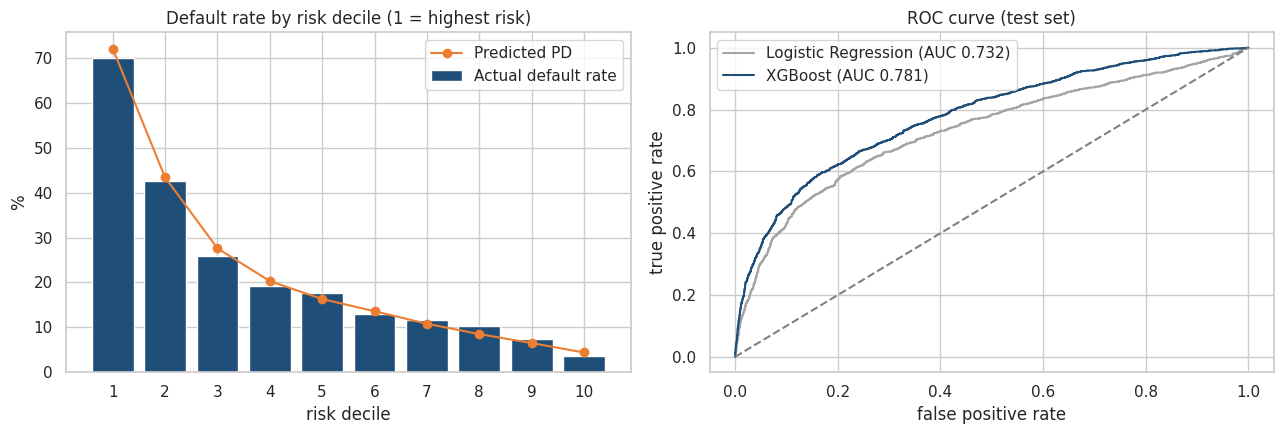

In [7]:
fig, ax = plt.subplots(1,2, figsize=(13,4.5))
ax[0].bar(bands.index, bands.actual_default_rate, color="#1F4E79", label="Actual default rate")
ax[0].plot(bands.index, bands.predicted_pd, "o-", color="#ED7D31", label="Predicted PD")
ax[0].set(title="Default rate by risk decile (1 = highest risk)", xlabel="risk decile", ylabel="%", xticks=range(1,11)); ax[0].legend()
for name,m,c in [("Logistic Regression",lr,"#A5A5A5"),("XGBoost",xgb,"#1F4E79")]:
    f,tp,_ = roc_curve(yte, m.predict_proba(Xte)[:,1]); ax[1].plot(f,tp,label=f"{name} (AUC {roc_auc_score(yte,m.predict_proba(Xte)[:,1]):.3f})",color=c)
ax[1].plot([0,1],[0,1],"--",color="grey"); ax[1].set(title="ROC curve (test set)", xlabel="false positive rate", ylabel="true positive rate"); ax[1].legend()
plt.tight_layout(); plt.savefig("charts/risk_deciles_and_roc.png", dpi=150); plt.show()

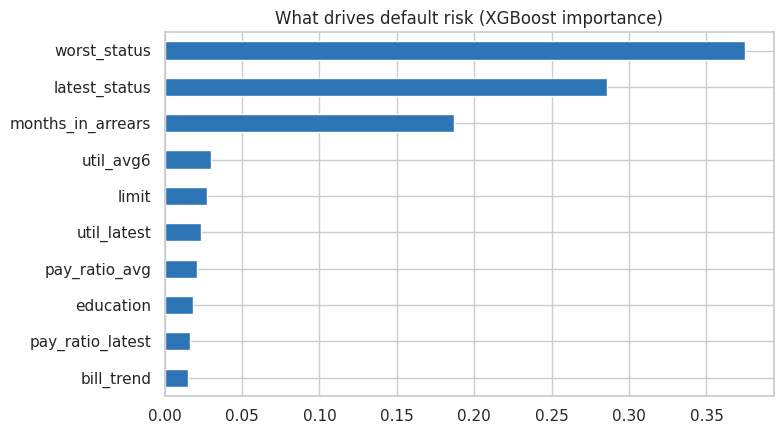

In [8]:
imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()
ax = imp.plot.barh(figsize=(8,4.5), color="#2E75B6"); ax.set(title="What drives default risk (XGBoost importance)")
plt.tight_layout(); plt.savefig("charts/feature_importance.png", dpi=150); plt.show()

## 6. Responsible-use check: outcomes by group (protected characteristics not used as inputs)

In [9]:
g = df.loc[ite, ["SEX"]].assign(pd=p, default=yte.values, flagged=(t.risk_decile.values<=2))
g["SEX"] = g.SEX.map({1:"male",2:"female"})
print(g.groupby("SEX").agg(customers=("pd","size"), actual_default_pct=("default","mean"), mean_predicted_pd=("pd","mean"), flagged_top20_pct=("flagged","mean")).mul([1,100,100,100]).round(1).to_string())

        customers  actual_default_pct  mean_predicted_pd  flagged_top20_pct
SEX                                                                        
female       4517                21.2               22.0               19.2
male         2983                23.5               22.9               21.2
